# Event study: abnormal returns by news type

Abnormal return (AR) = stock return minus VN-Index return, from the close of session -1 to the close of session k-1 (k = 1, 3, 5). Data: `data/processed/event_returns.csv` from `python -m src.event_study.event_returns`.

In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd

from src.event_study.config import EVENT_RETURNS_CSV
from src.event_study.summary import event_summary, plot_mean_ar

In [2]:
returns = pd.read_csv(EVENT_RETURNS_CSV)
summary = event_summary(returns)
returns.groupby("k")["abnormal_return"].count()

k
1    169
3    169
5    169
Name: abnormal_return, dtype: int64

## Results table

Mean, median, sd and CI are in %. 12 tests per sample (4 labels x 3 windows), so some p < 0.05 can appear by chance.

In [3]:
pct = ["mean", "median", "std", "ci_low", "ci_high"]
table = summary.copy()
table[pct] = table[pct] * 100
table.round({c: 2 for c in pct} | {"pct_positive": 2, "t_pvalue": 3, "wilcoxon_pvalue": 3})

,sample,label,k,n,mean,median,std,pct_positive,ci_low,ci_high,t_pvalue,wilcoxon_pvalue
0,all,business_results,1,65,-0.16,-0.08,1.66,0.46,-0.57,0.25,0.445,0.390
1,all,business_results,3,65,-0.49,-1.02,2.88,0.37,-1.20,0.23,0.178,0.053
2,all,business_results,5,65,-0.10,-0.32,3.81,0.46,-1.05,0.84,0.831,0.688
3,all,dividends_issuance,1,33,0.10,-0.24,1.80,0.36,-0.53,0.74,0.744,0.502
4,all,dividends_issuance,3,33,0.60,0.20,3.61,0.55,-0.68,1.88,0.348,0.584
5,all,dividends_issuance,5,33,0.18,-0.11,5.31,0.48,-1.71,2.06,0.851,0.874
6,all,legal_personnel,1,22,-0.09,-0.23,2.25,0.41,-1.09,0.90,0.847,0.566
7,all,legal_personnel,3,22,-0.25,-1.13,4.59,0.32,-2.28,1.79,0.804,0.545
8,all,legal_personnel,5,22,-0.24,-0.44,5.99,0.45,-2.89,2.42,0.855,0.633
9,all,ma_investment,1,49,-0.02,-0.23,1.81,0.37,-0.54,0.50,0.951,0.168


## Mean AR by label (all events)

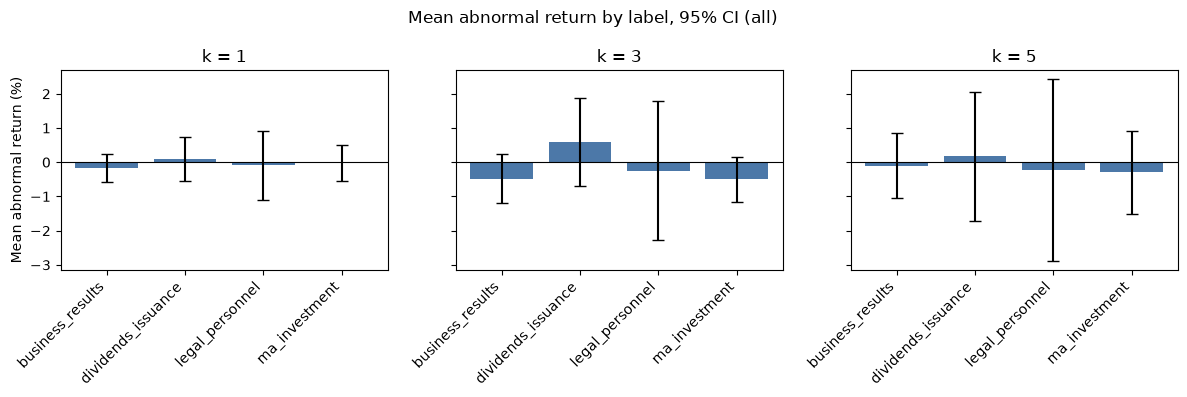

In [4]:
plot_mean_ar(summary, "all");

## Robustness: without VIC

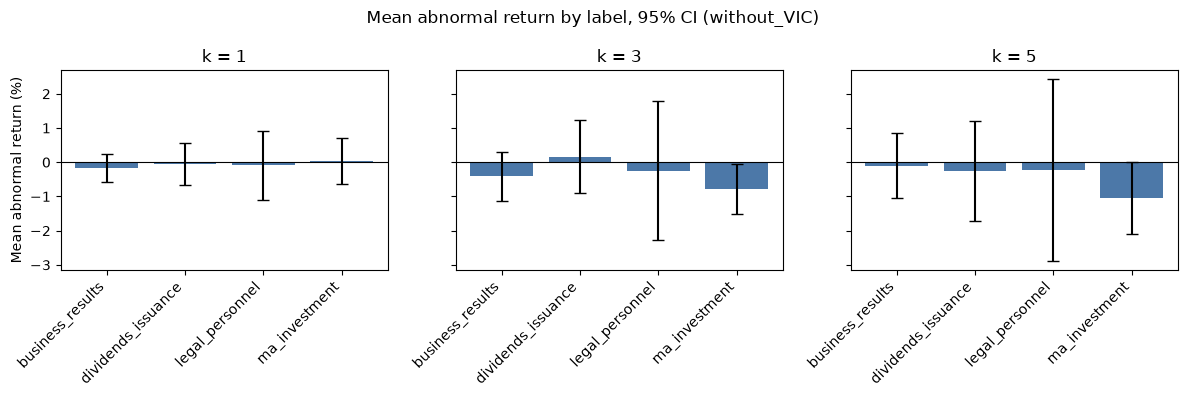

In [5]:
plot_mean_ar(summary, "without_VIC");